                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                                 
2021-10-11 00:10:00         1          284        1     0           0
2021-10-11 00:11:00         1          284        1     0           0
2021-10-11 00:12:00         1          284        1     0           0
2021-10-11 00:13:00         1          284        1     0           0
2021-10-11 00:14:00         1          284        1     0           0
...                       ...          ...      ...   ...         ...
2022-01-14 23:56:00         1           14        5    23           0
2022-01-14 23:57:00         1           14        5    23           0
2022-01-14 23:58:00         1           14        5    23           0
2022-01-14 23:59:00         1           14        5    23           0
2022-01-15 00:00:00         1           15        6     0           0

[110585 rows x 5 columns]


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:               Parkings   No. Observations:               110585
Model:                 ARIMA(5, 1, 0)   Log Likelihood             -360363.202
Date:                Thu, 06 Jun 2024   AIC                         720738.405
Time:                        21:46:35   BIC                         720796.086
Sample:                             0   HQIC                        720755.831
                             - 110585                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2174      0.002    116.824      0.000       0.214       0.221
ar.L2          0.0649      0.002     36.267      0.000       0.061       0.068
ar.L3          0.0527      0.002     25.609      0.0

c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


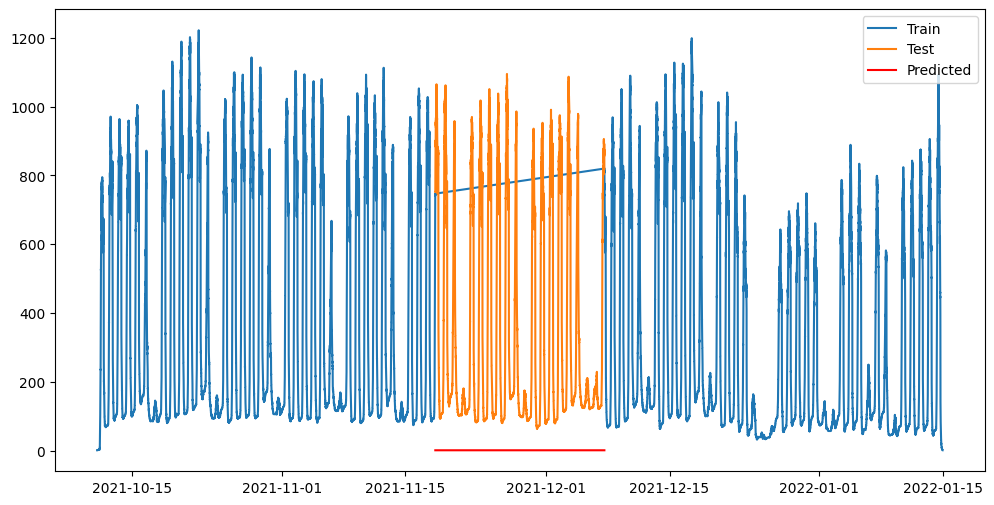

Root Mean Squared Error: 467.2740579688425


: 

In [1]:
import pandas as pd
from datetime import datetime, timedelta
import holidays
from sklearn.metrics import mean_squared_error
import numpy as np


# Read the CSV file into a DataFrame
df = pd.read_csv('../data/Turkuparkkihub_parkings_anon.csv', delimiter=';')

# Convert 'time_start' and 'time_end' columns to datetime type
df['time_start'] = pd.to_datetime(df['time_start'], format='%d/%m/%Y %H.%M', errors='coerce')
df['time_end'] = pd.to_datetime(df['time_end'], format='%d/%m/%Y %H.%M', errors='coerce')

# Filter the DataFrame to cover the specified time period
start_date = datetime(2021, 10, 11)
end_date = datetime(2022, 1, 15)
df_filtered = df[(df['time_start'] >= start_date) & (df['time_end'] <= end_date)]

# Function to round datetime to nearest minute
def round_to_minute(dt):
    return dt - timedelta(seconds=dt.second, microseconds=dt.microsecond)

# Initialize time series data
time_series = {}

# Iterate through each row in the filtered DataFrame
for index, row in df_filtered.iterrows():
    time_start = row['time_start']
    time_end = row['time_end']

    current_time = round_to_minute(time_start)
    while current_time <= time_end:
        if current_time not in time_series:
            time_series[current_time] = 0
        time_series[current_time] += 1
        current_time += timedelta(minutes=1)

# Convert time series data to DataFrame
time_series_df = pd.DataFrame(list(time_series.items()), columns=['Time', 'Parkings'])

# Sort DataFrame in ascending order based on the datetime column
time_series_df = time_series_df.sort_values(by='Time', ascending=True)

# Extract additional features
time_series_df['day_of_year'] = time_series_df['Time'].dt.dayofyear
time_series_df['weekday'] = time_series_df['Time'].dt.weekday + 1  # Monday=1, Sunday=7
time_series_df['hour'] = time_series_df['Time'].dt.hour

# Generate holiday dates for the relevant years (assuming Finland's holidays)
finland_holidays = holidays.Finland(years=time_series_df['Time'].dt.year.unique())

# Define a function to check if a date is a holiday or Sunday
def is_holiday_or_sunday(date):
    return date in finland_holidays or date.weekday() == 6  # Sunday is 6 in datetime

# Apply the function to create the is_holiday column
time_series_df['is_holiday'] = time_series_df['Time'].apply(lambda x: 1 if is_holiday_or_sunday(x) else 0)

# Calculate the number of rows for each split
n = len(time_series_df)
train_size = int(n * 0.4)
test_size = int(n * 0.2)

# Define the indices for splitting
train_start_idx = 0
train_end_idx = train_size
test_start_idx = train_end_idx
test_end_idx = test_start_idx + test_size
train_end2_idx = n

# Split the data
train_start = time_series_df.iloc[:train_end_idx]
test = time_series_df.iloc[test_start_idx:test_end_idx]
train_end = time_series_df.iloc[test_end_idx:train_end2_idx]

# Combine training data
train = pd.concat([train_start, train_end])

# Set 'Time' as index
train.set_index('Time', inplace=True)
test.set_index('Time', inplace=True)
print(train)

# Ensure the 'Time' column is a datetime index
train.index = pd.to_datetime(train.index)
test.index = pd.to_datetime(test.index)

# Fit the ARIMA model
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

model = ARIMA(train['Parkings'], order=(5, 1, 0))  # Adjust p, d, q as needed
model_fit = model.fit()

# Print the model summary
print(model_fit.summary())

# Predict using the fitted model
pred_start = len(train)
pred_end = len(train) + len(test) - 1
predictions = model_fit.predict(start=pred_start, end=pred_end, dynamic=False)

# Adjust the index of predictions to match the test set
predictions.index = test.index

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train.index, train['Parkings'], label='Train')
plt.plot(test.index, test['Parkings'], label='Test')
plt.plot(test.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()

# Calculate evaluation metrics
mse = mean_squared_error(test['Parkings'], predictions)
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse}')
